# From multivariate recordings to a changing system coordinate

**Collective period-two order → harmonic locking under variable recording quality → measured frequency locking.** Compare dependence profiles within each recording; ask which relationships drive the dominant coordinate across recordings. Each system retains its own frozen model.

In [1]:
from pathlib import Path
import os, sys
for key in ('OPENBLAS_NUM_THREADS','OMP_NUM_THREADS','MKL_NUM_THREADS'):
    os.environ[key] = '1'
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'src/mtsspi').is_dir())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from IPython.display import display, Image
from research.inference.benchmarks.three_systems import (
    style, load_cml, load_locking, load_hardware, draw_overview,
    draw_cml, draw_locking, draw_hardware, write_receipt)
from research.inference.benchmarks.coordinate_features import (
    feature_banks, gallery, edges)
style()
cml, locking, hardware = load_cml(), load_locking(), load_hardware()
banks = feature_banks(cml, locking, hardware)
def show(path):
    if path is not None:
        compact = 'loadings-' in path.name or 'edge-profiles' in path.name
        display(Image(filename=str(path), width=1000 if compact else None))
def loadings(key):
    show(gallery(banks[key]))
    show(gallery(banks[key], filtered=True))
print('Validated frozen scores/loadings, source hashes, and original ordered-edge profiles; no SPI extraction or refitting.')


Validated frozen scores/loadings, source hashes, and original ordered-edge profiles; no SPI extraction or refitting.


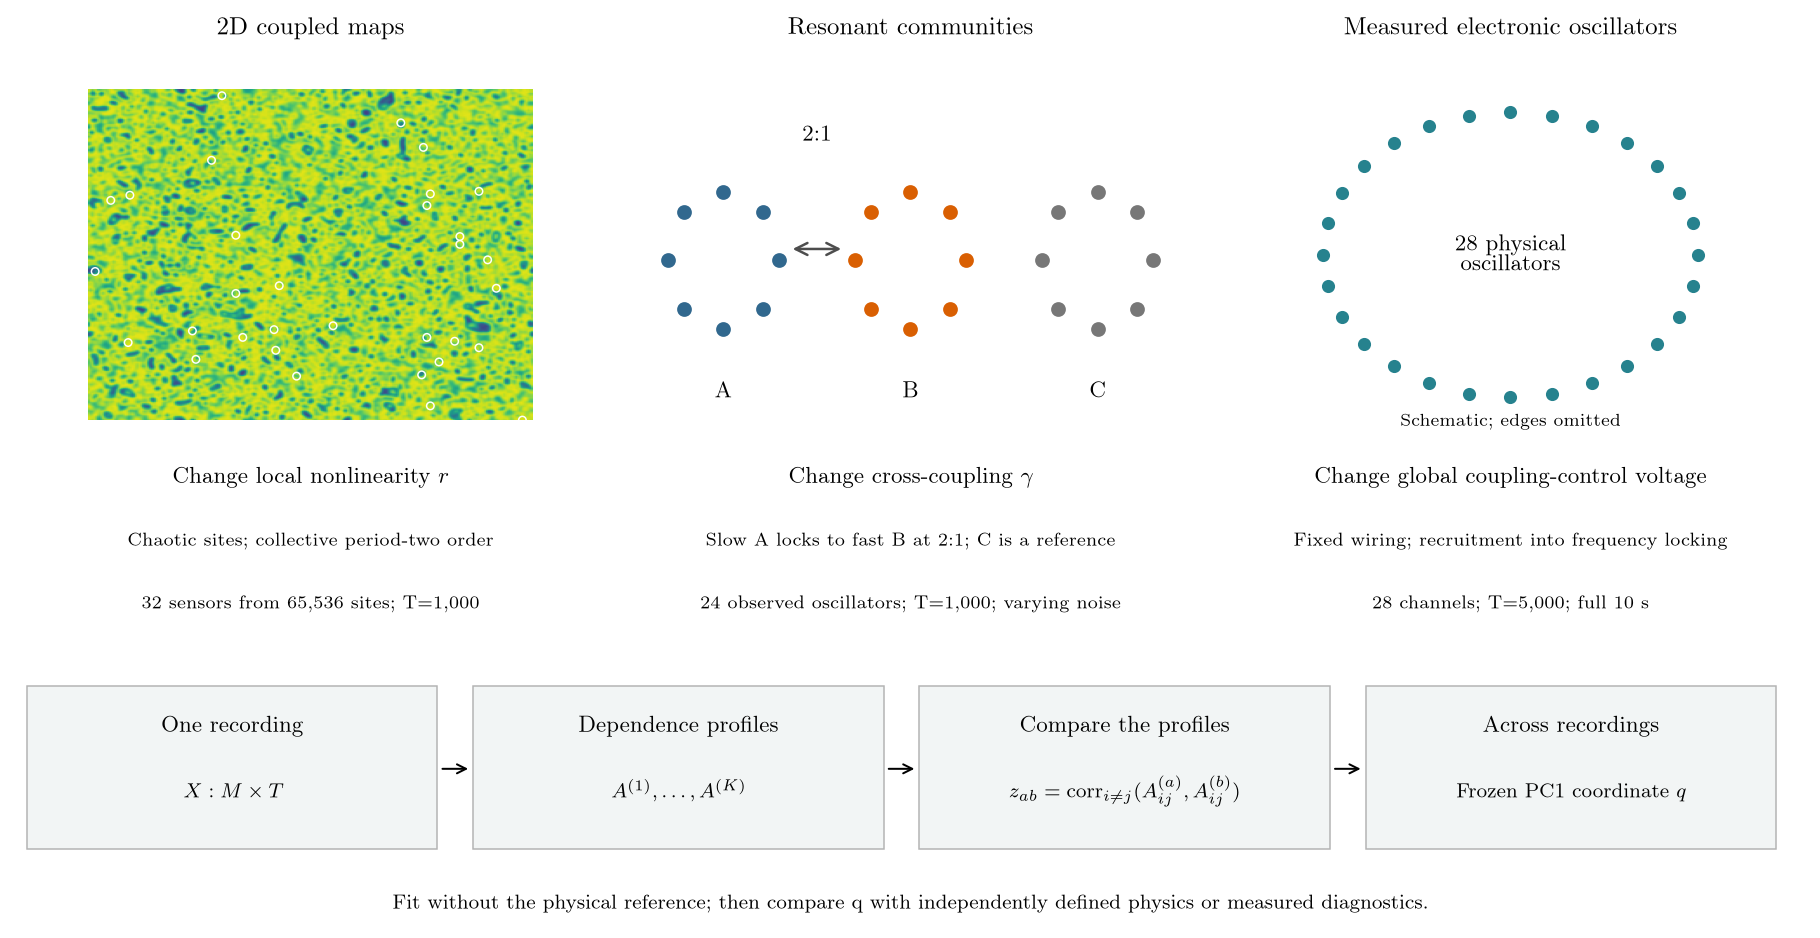

In [2]:
show(draw_overview(cml))

**Readout panels:** $z$-PC1 → mean-MPI PC1 → mean-$|r|$ for the synthetic systems. Mean-MPI PC1 reduces the vector of edge-averaged SPI values using its original development-fitted scaling; $z$-PC1 reduces agreement between edge profiles. Black is the physical reference; teal is the readout, with independent vertical scales and original signs. Bands are 10–90% instance ranges, not confidence intervals. Heatmaps use full-record robust channel scaling; only the displayed time range is cropped.

**Feature panels:** top 16 by $|w|$, with signed PC1 coefficients and held feature curves; then the same ranking excluding pairs of classical correlations and numerically duplicate displayed curves. These are display filters, not evidence of spuriousness; PC1 is unchanged. Identical filtered panels are omitted. Hardware shows ER (teal) and small-world (orange), without replicate bands; gallery voltage axes are linear to .2 V and logarithmic above, to resolve the locking region. A large loading is not a unique mechanistic contribution. Edge plots use all ordered off-diagonal entries, original units, and common limits per row; symmetric entries overlap. Exact SPI names, coefficients and replay checks are exported beside the figures.

## 1 · CML2D: collective period-two order

A periodic **256×256 lattice** of chaotic logistic maps has fixed four-neighbour coupling g=.2. Increasing local nonlinearity r merges the alternating global-mean levels. Observe **32 dispersed sites × 1,000 steps**. The system is $x_i(t+1)=(1-4g)f_r(x_i(t))+g\sum_{j\in\mathrm{nn}(i)}f_r(x_j(t))$, with $f_r(x)=rx(1-x)$. The reference $Q=\langle|\bar x(2t+1)-\bar x(2t)|\rangle$ uses a disjoint million-step window. [Model and order parameter](https://arxiv.org/abs/nlin/0605004).

**Test:** recover collective order from sparse dependence profiles. Fit on four development seeds; confirm on **32 fresh seeds × 17 controls**. Upper examples use a fixed original held seed; bottom curves use independent confirmation. The dotted infinite-size boundary is a numerical reference.

The row below the observed-channel heatmaps shows the **full 256×256 lattice**, with sensor positions marked in white. These are archived final states after the future reference window, at the same control/seed as the portraits above; they are spatial illustrations, not simultaneous snapshots of the displayed observations.

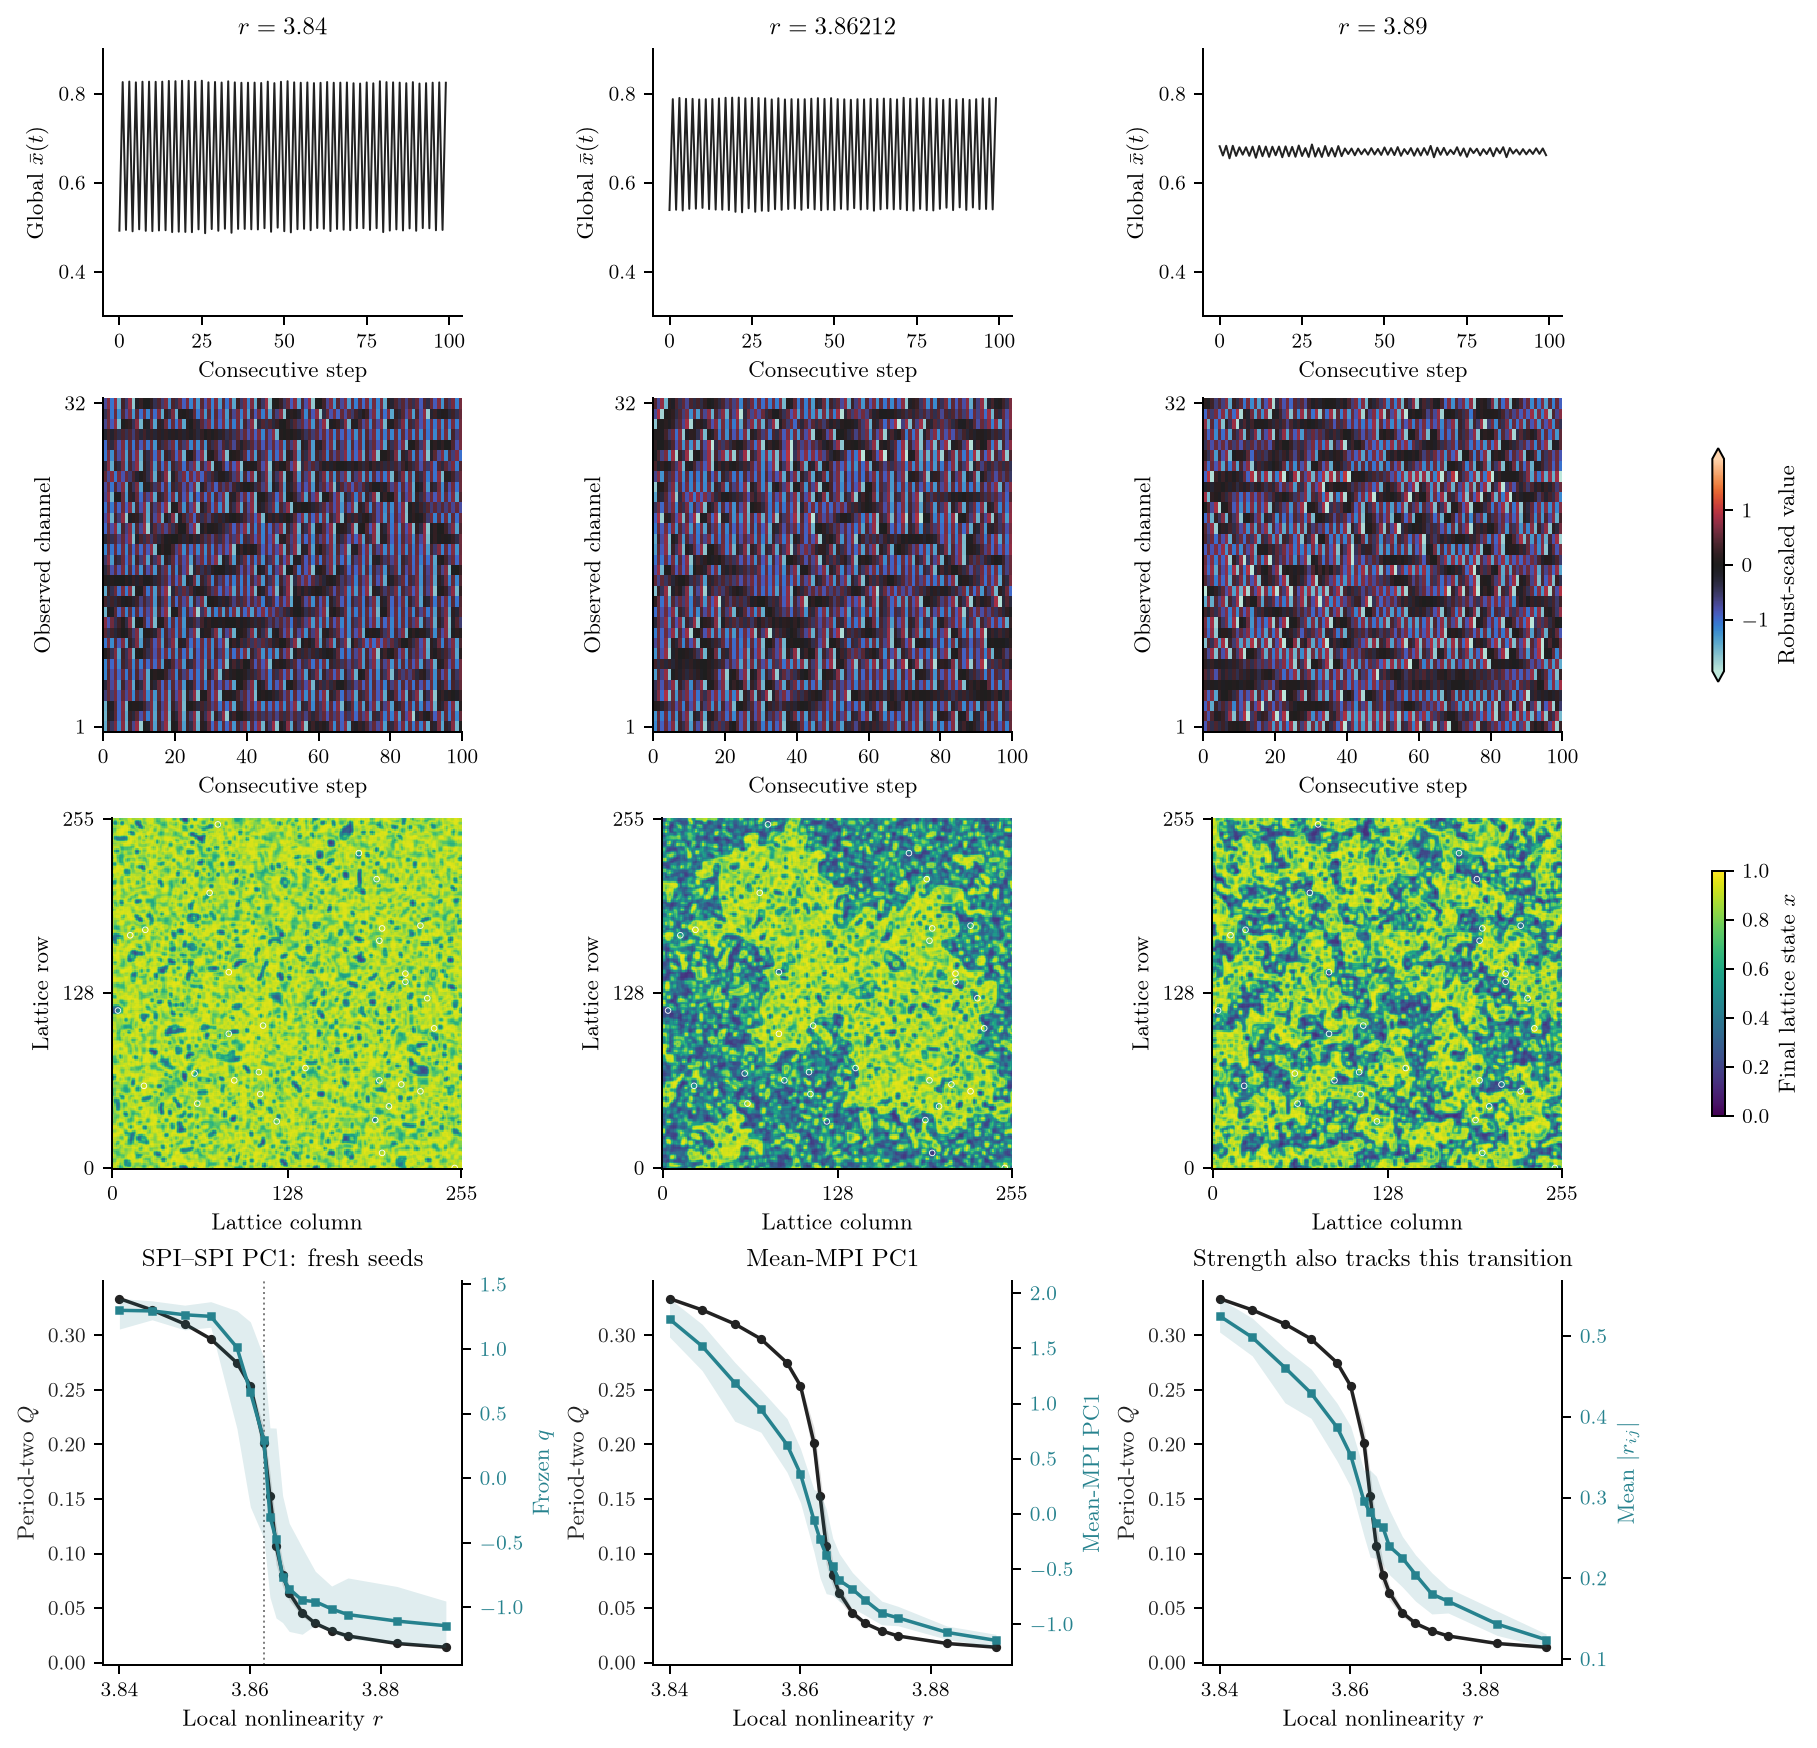

In [3]:
show(draw_cml(cml))

Frozen q tracks Q (ρ=.883); mean absolute Pearson is stronger (.966). This demonstrates transition sensitivity, not baseline superiority.

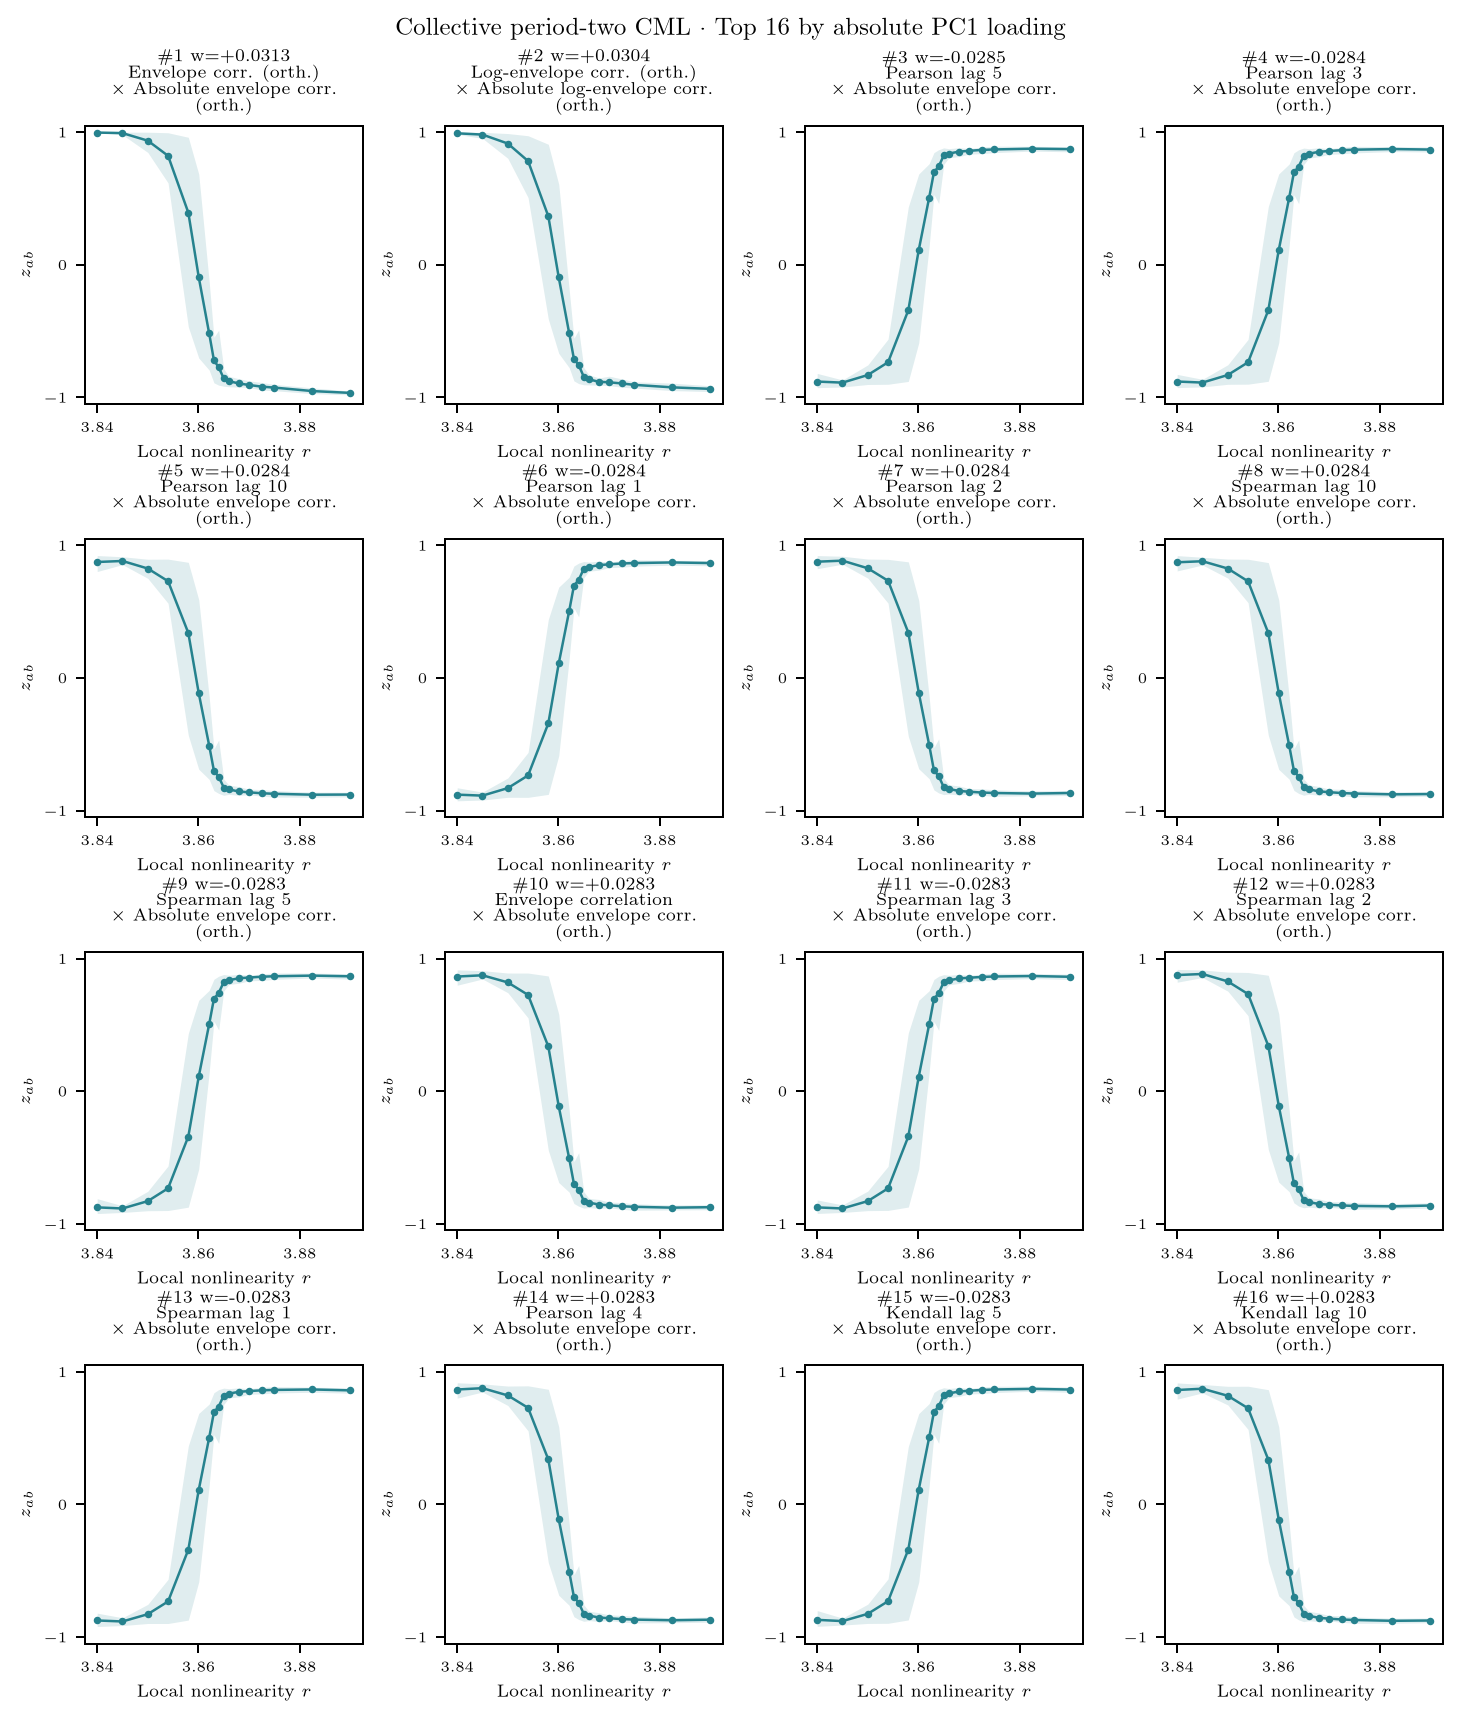

Collective period-two CML: filtering leaves the top 16 unchanged; duplicate panel omitted.


In [4]:
loadings('cml2d')

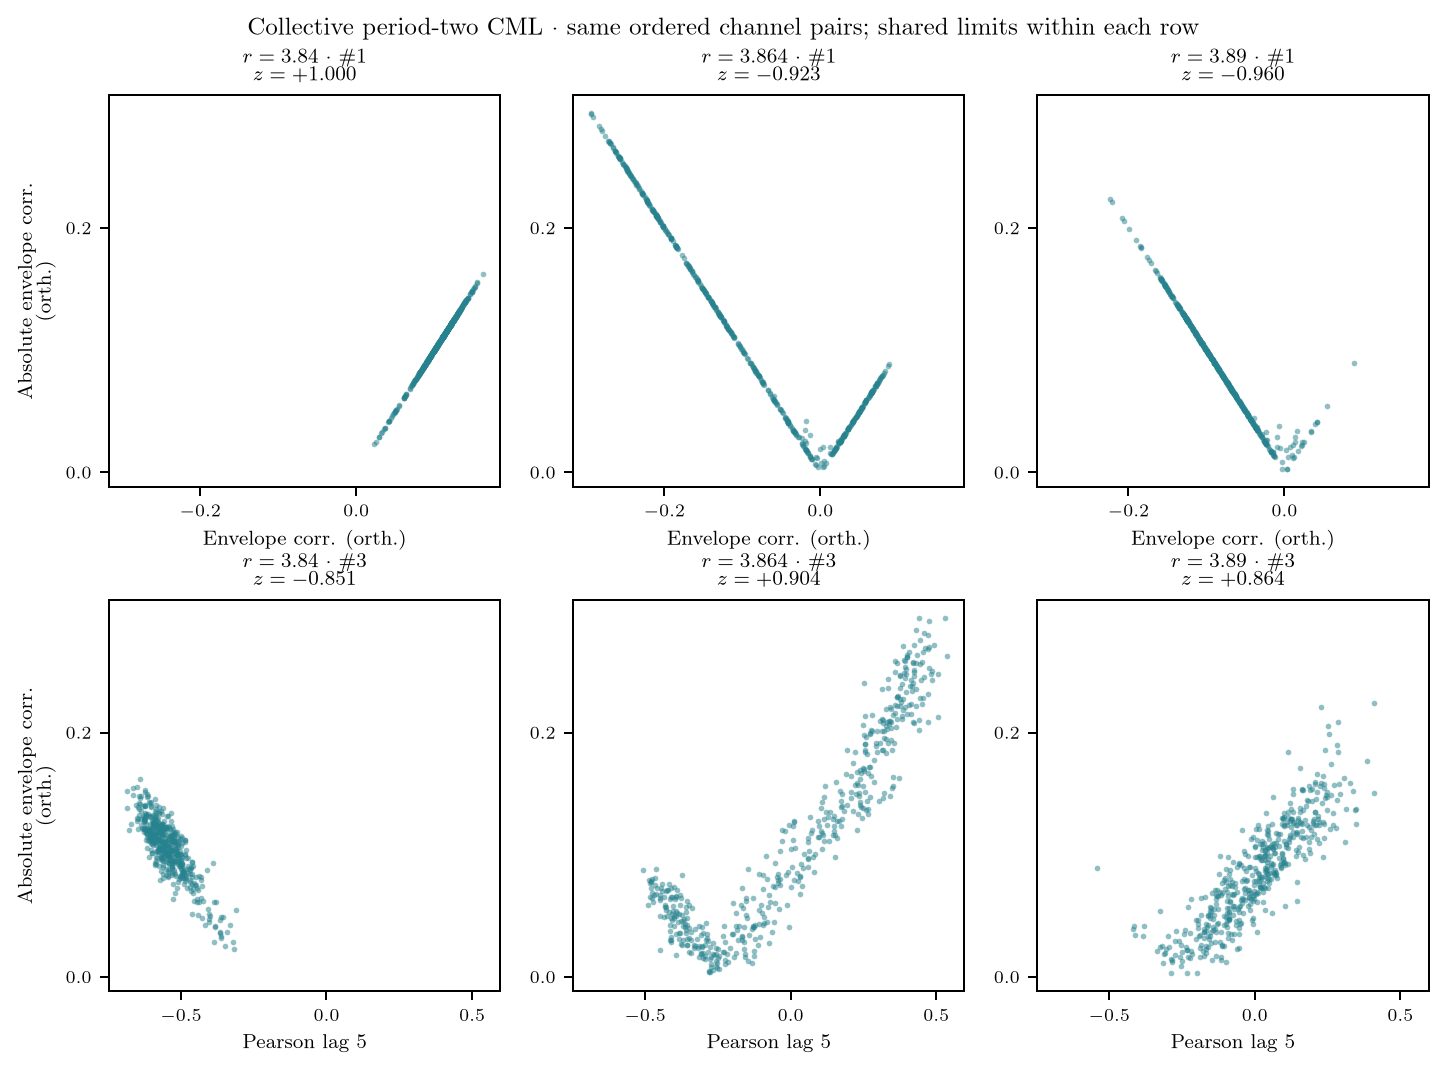

In [5]:
show(edges(banks['cml2d'], 'cml2d'))

The leading contrast is **signed versus absolute orthogonalised envelope correlation**: the example profiles shift from positive agreement to predominantly negative signed values. Its reversal is partly the geometry of taking an absolute value, not two independently recovered mechanisms. Lag-5 Pearson versus the absolute profile also reverses (−.85→+.86). Odd/even-lag loading signs are consistent with alternating dynamics; these are descriptive signatures, not evidence of a separate amplitude-coupling mechanism.

## 2 · Noisy harmonic locking: prioritise dynamics over recording quality

Three eight-oscillator communities: **slow A and fast B couple resonantly; C is a reference**. Increase cross-coupling γ toward 2:1 locking. Observe **24 channels × 1,000 samples**. Each recording receives independent sensor noise with amplitude η∼U[.3,.9], independent of γ; η is shared across channels, noise realisations are not. [Underlying model](https://arxiv.org/abs/1502.06193), modified by finite populations, noise and community C.

**Test:** does PC1 prioritise locking over noise? Fit eight seeds, evaluate eight held seeds at each of **21 controls**. Q measures harmonic phase alignment in a disjoint future window. Displayed noisy observations are selected nearest η=.6 at γ=0/.10/.20, without consulting Q/q. The dotted threshold is an approximate reduced-model reference.

With $Z_{A,k}=\langle e^{ik\phi}\rangle_A$, $Z_B=\langle e^{i\psi}\rangle_B$ and $Z_C=\langle e^{i\chi}\rangle_C$, the simulated dynamics are
$$
\begin{aligned}
d\phi_i&=[\omega_i+\epsilon\,\mathrm{Im}(Z_{A,1}e^{-i\phi_i})+\gamma\,\mathrm{Im}(Z_Be^{-2i\phi_i})]dt+\sigma\,dW_i,\\
d\psi_i&=[\nu_i+\epsilon\,\mathrm{Im}(Z_Be^{-i\psi_i})+\gamma\,\mathrm{Im}(Z_{A,2}e^{-i\psi_i})]dt+\sigma\,dV_i,\\
d\chi_i&=[\xi_i+\epsilon\,\mathrm{Im}(Z_Ce^{-i\chi_i})]dt+\sigma\,dU_i.
\end{aligned}
$$
Here $\epsilon=.5$, $\sigma=.1$, and mean intrinsic frequencies are $1,2.3,1.37$; $W,V,U$ are independent Wiener noises. The observation is a standardised noisy sine of phase. The reference $Q=|\langle e^{i(\arg Z_B-\arg Z_{A,2})}\rangle_{\rm future}|$ measures constancy of the slow community's doubled phase relative to the fast community: near 1 means 2:1 locking, even though their waveforms need not match.

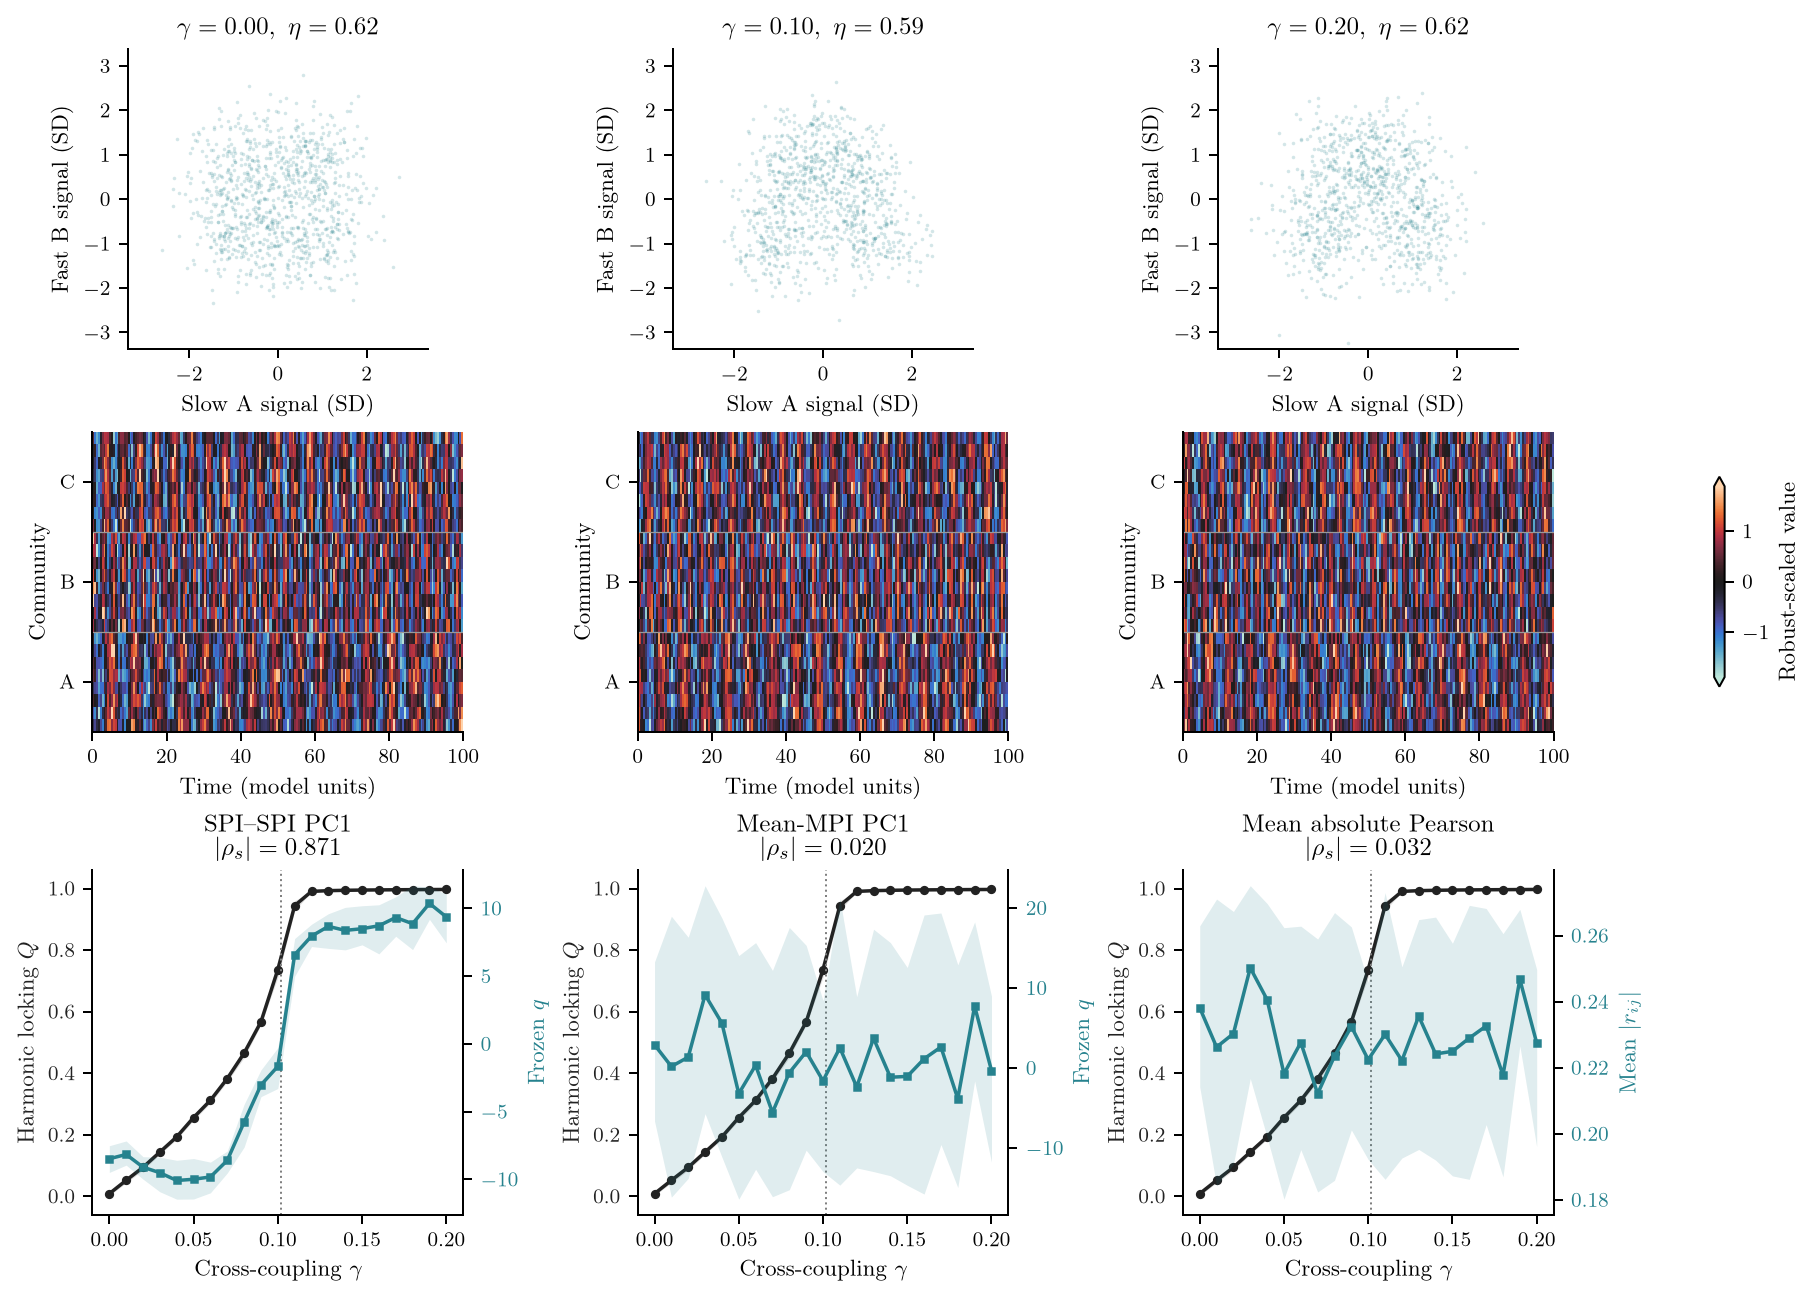

In [6]:
show(draw_locking(locking))

Held association with Q: **.871 / .032 / .020** for SPI–SPI PC1 / mean absolute Pearson / mean-SPI PC1. Locking information remains in later mean-SPI components. Existing M48 confirmation gives .855/.133/.115.

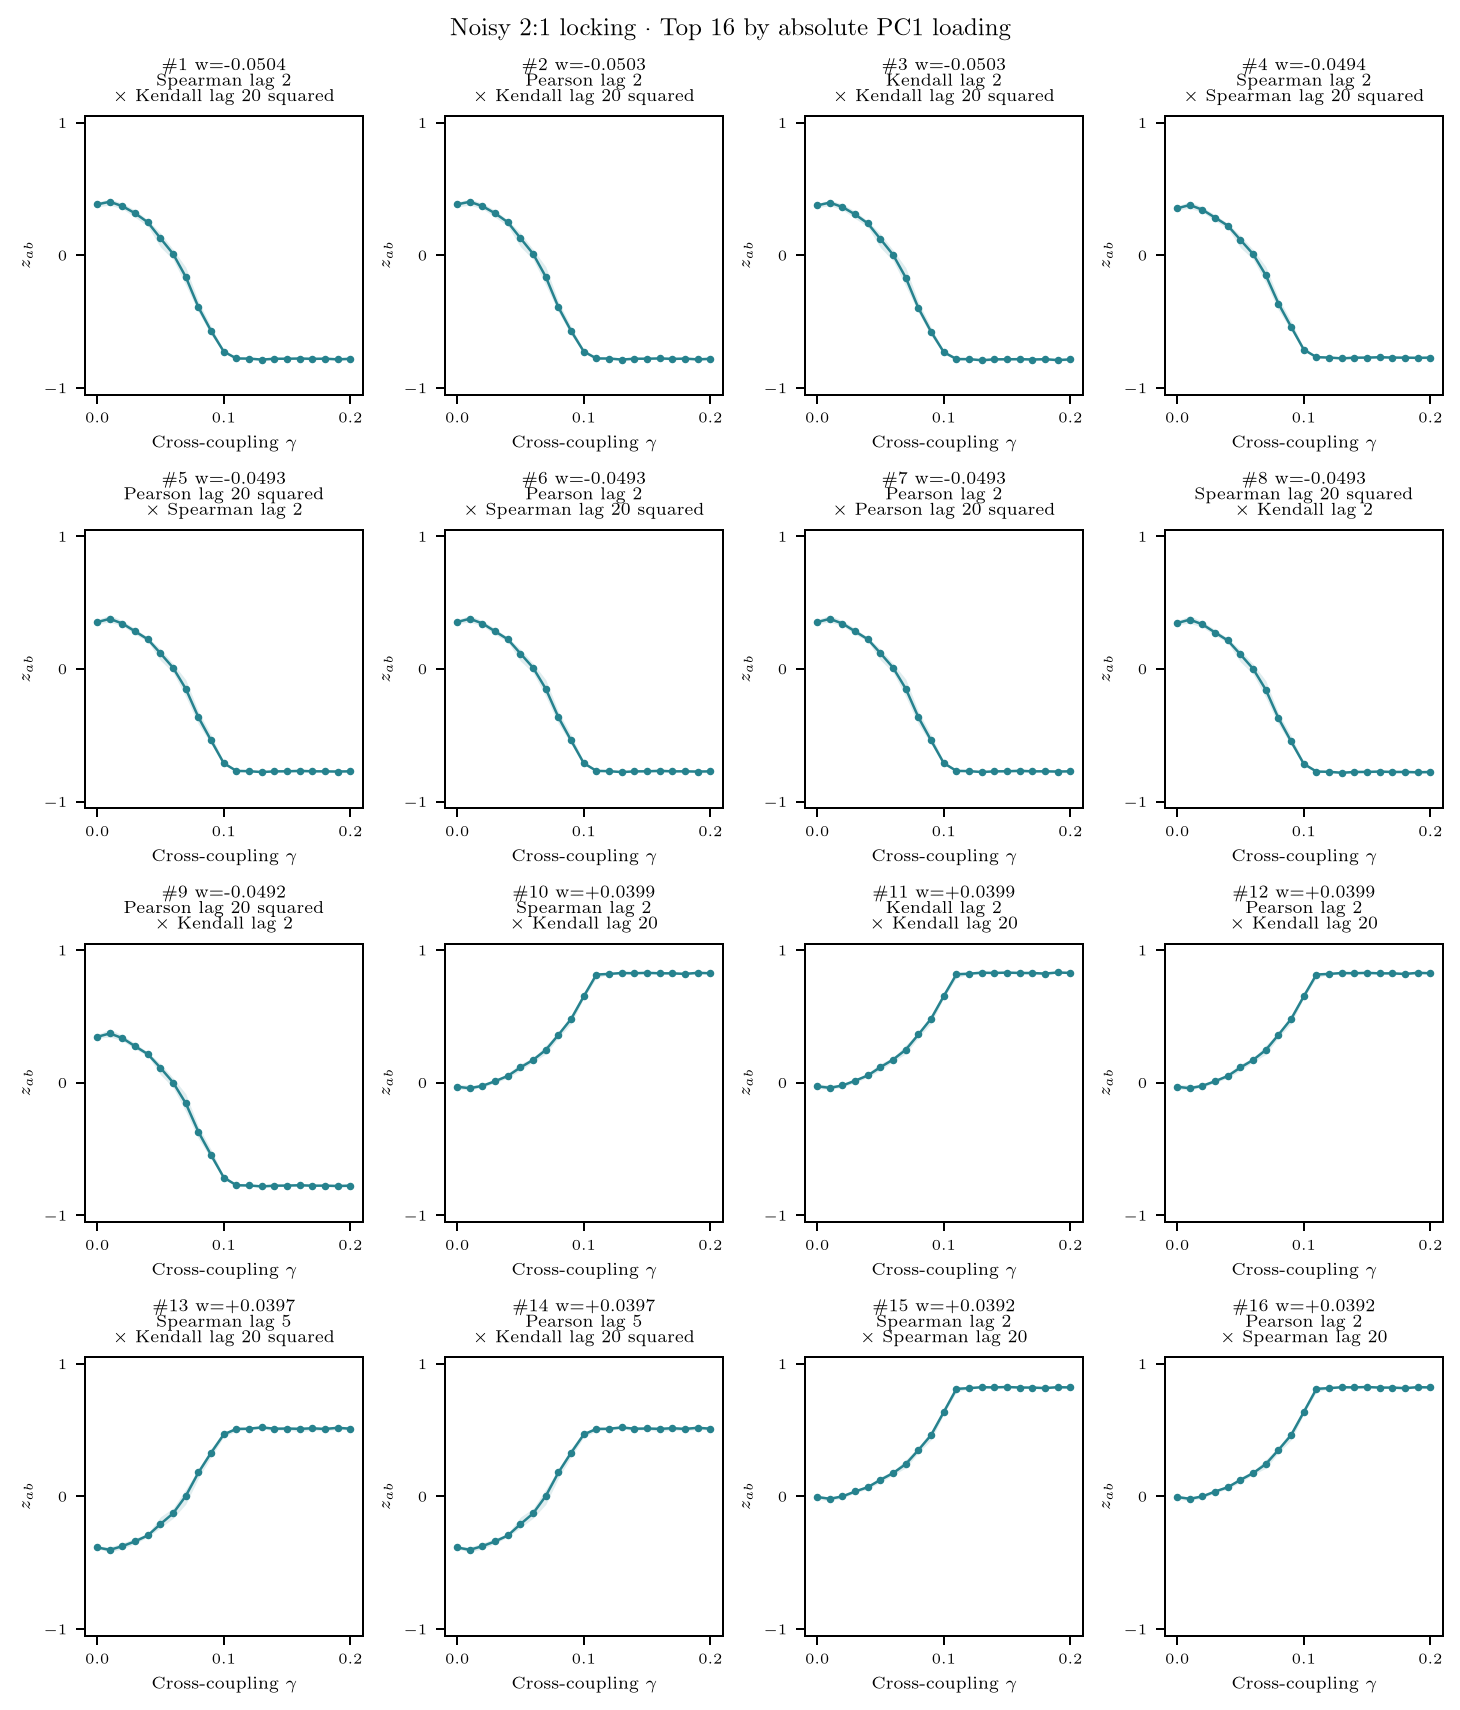

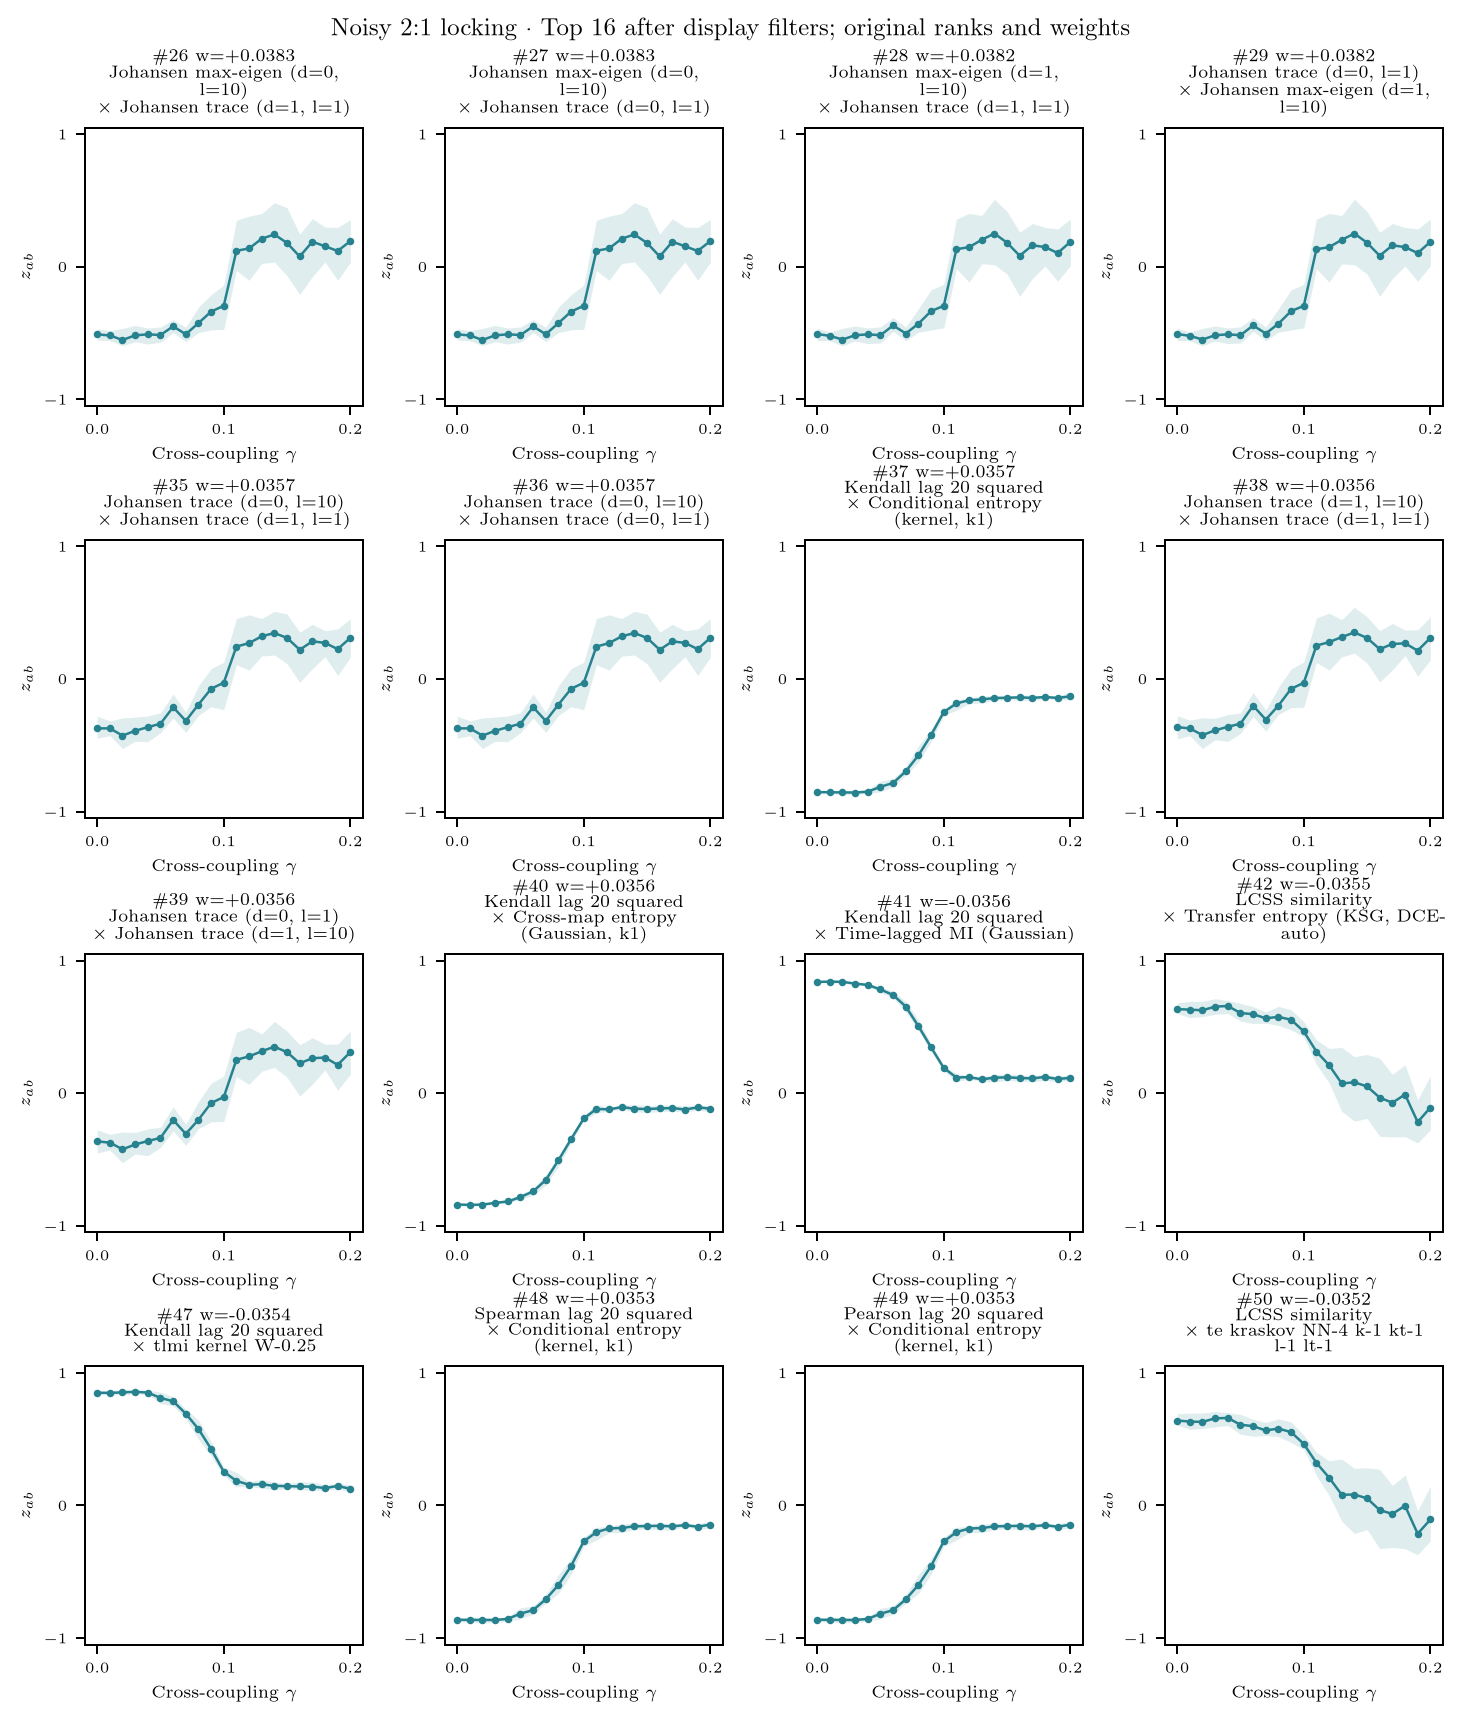

In [7]:
loadings('locking')

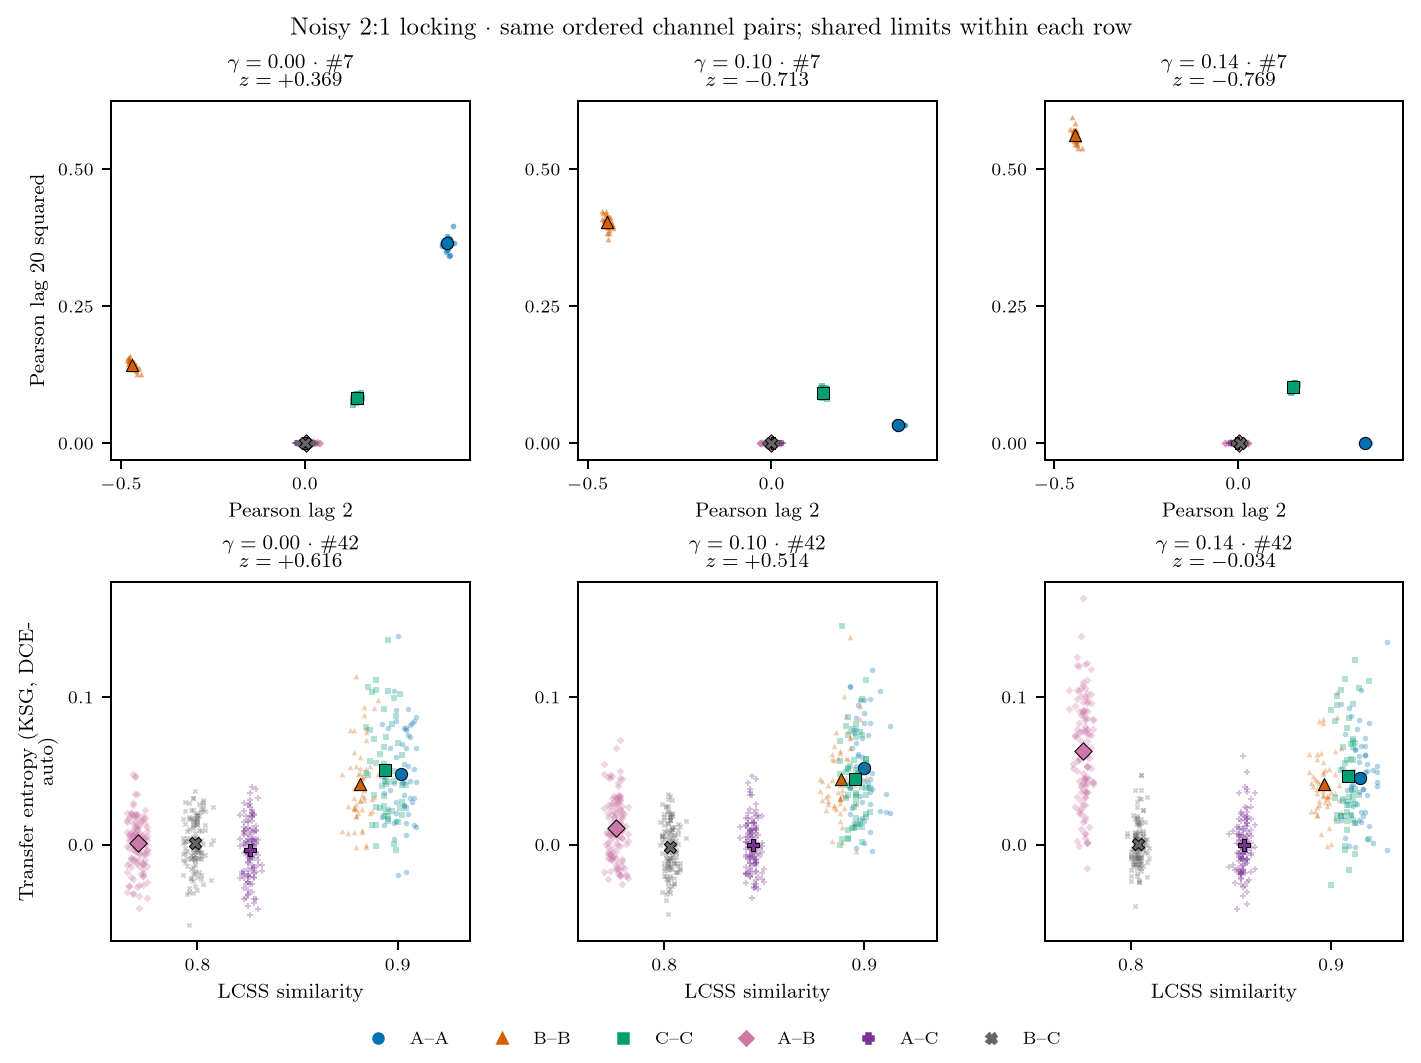

In [8]:
show(edges(banks['locking'], 'locking'))

The lagged pair resolves **redistribution of temporal dependence between A and B**; community C stays comparatively stable. For LCSS versus transfer entropy, A–B predictive dependence rises while waveform similarity barely changes. Colours identify community pairs; outlined markers are their means. These fixed γ=0/.10/.14 examples use held records nearest η=.6, so noise and initial conditions differ. The contrasts explain two contributions to a mixed PC1, without uniquely isolating nonlinear coupling from frequency changes.

## 3 · Hardware: measured locking and transfer across wiring

**ER = Erdős–Rényi random wiring; SW = small-world wiring**, with mostly local connections and some long-range shortcuts. These are two network topologies, each connecting **28 analogue Rössler-like oscillators**, fixed diffusive coupling law and wiring within each sweep. Settings vary the global coupling-control voltage. From 701 settings each in [ER](https://zenodo.org/records/17451096) and [small-world](https://zenodo.org/records/17451530), use **29 ER + 16 small-world records**, retaining all channels and 10 s, anti-aliased to **500 Hz / T=5,000** after fidelity checks. Refinements target physically observed changes.

**Test:** fit ER alone, freeze, project small-world without imputation. All 45 version-consistent r9 extractions already exist. Reference: channel-frequency range in the 90–140 Hz component over the central 9 s; no universal Q is assumed. Snapshots focus on ER locking: relative phases use channel 1 and start at zero for display; heatmaps show unfiltered observations.

**Intuition:** these are 28 slightly mismatched physical oscillators connected by a fixed network. Turning one coupling knob changes how strongly they pull one another into step. A setting is one knob position and one 10-second multichannel recording, not a time window from a continuously swept trajectory. ER and small-world use different wiring; their locking thresholds need not coincide. The upper traces show channels slipping in phase before locking and settling to nearly fixed relative phases afterwards.

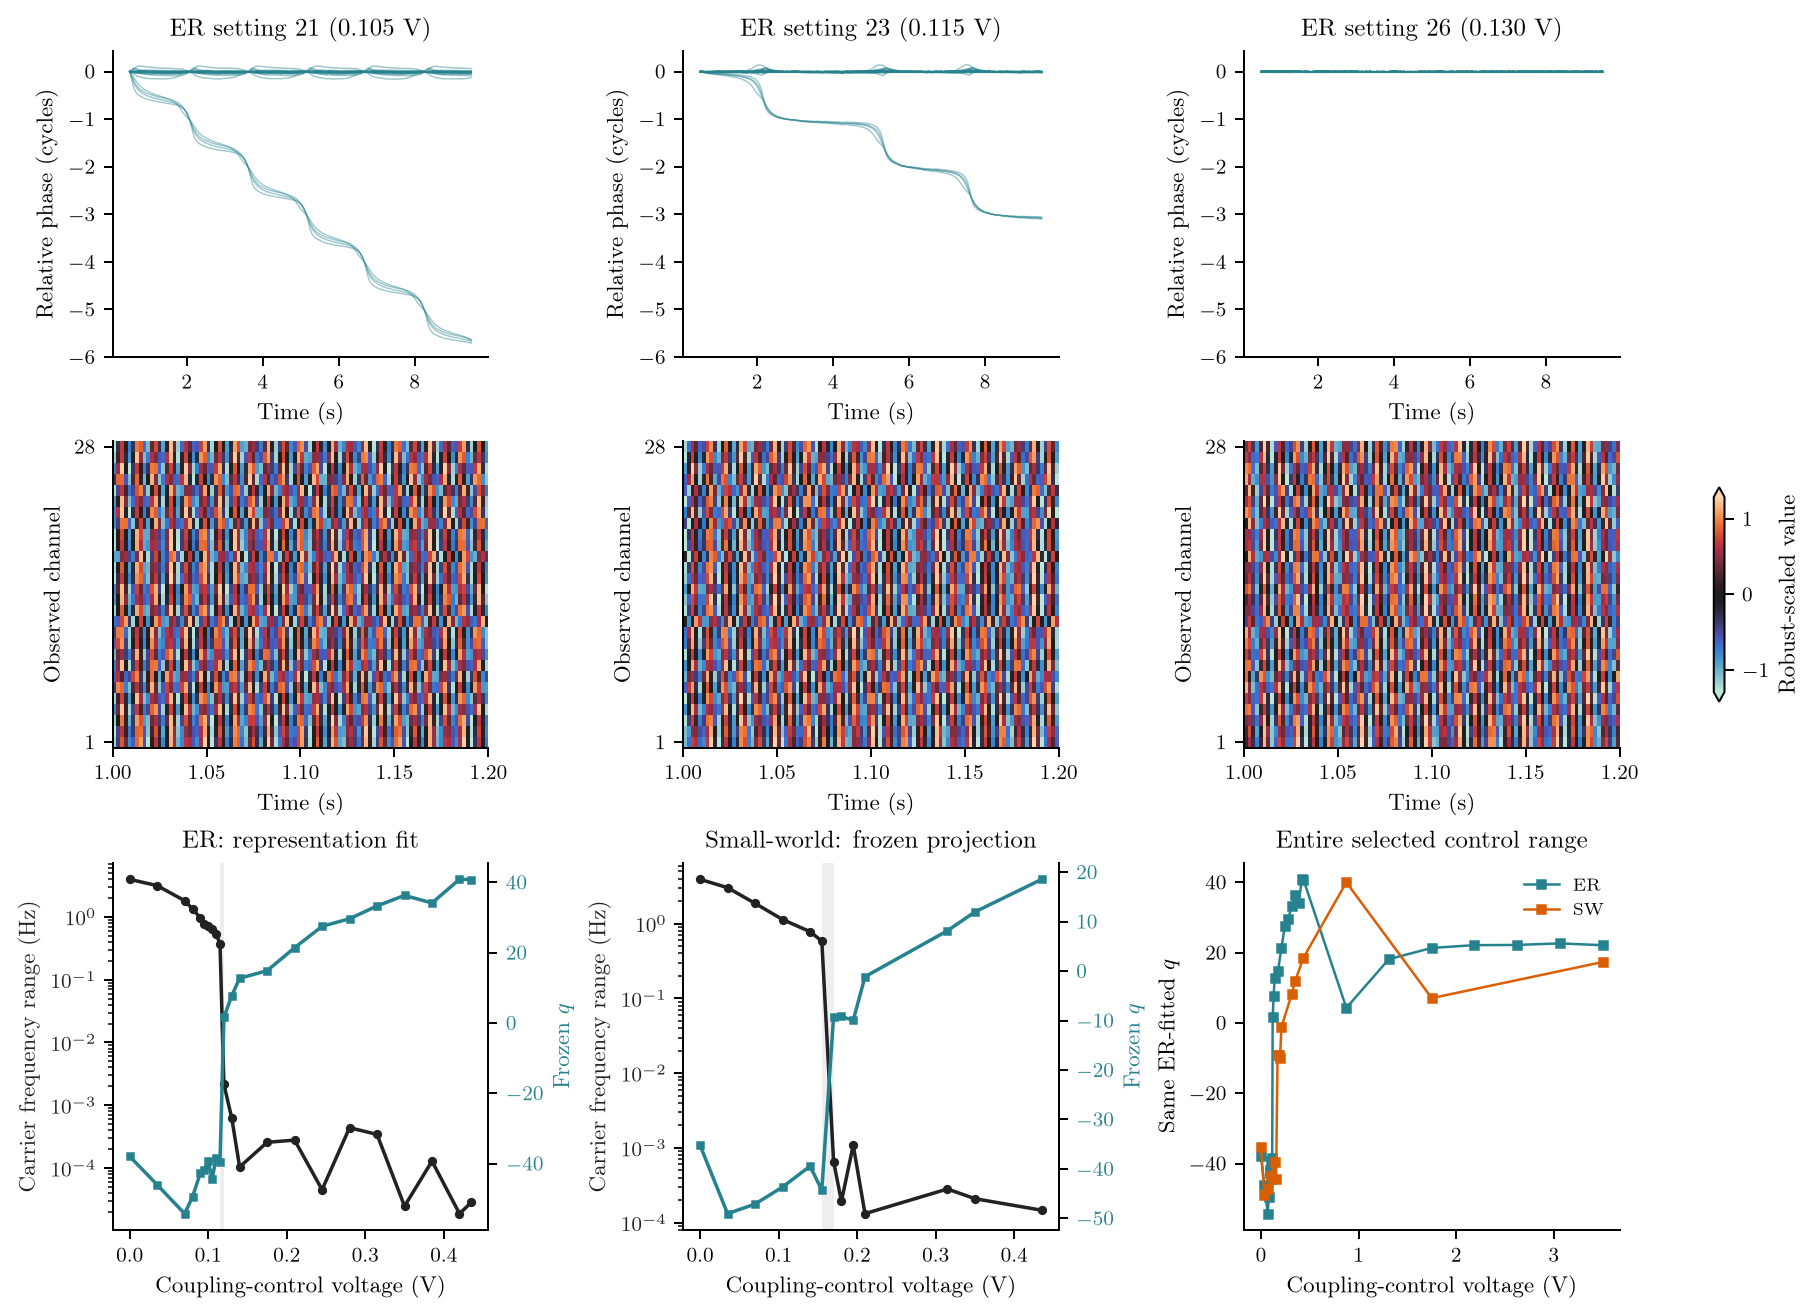

In [9]:
show(draw_hardware(hardware))

Largest adjacent PC1 changes coincide with locking: **ER 23→24** and **small-world 31→34**. ER PC1 explains 45.2%. This is exploratory cross-wiring transfer; PCA ordering depends on control sampling.

**Why does q change?** Kernel stochastic interaction × IDS reverses **+.534→−.905 ER; +.712→−.881 small-world**. The coherent core already has negative agreement before locking. Coloured edges show recruitment of previously less-coherent pairs, supported by bandwidth/window checks; the strong reversal remains estimator-family dependent.

**IDS = InterDependence Score**: a symmetric measure of contemporaneous dependence, including nonlinear relationships. This pyspi configuration takes the largest absolute correlation across six fixed nonlinear transforms of each channel (bandwidth .5). It contains no lag and does not identify direction or causality. [Method](https://github.com/aradha/interdependence_scores).

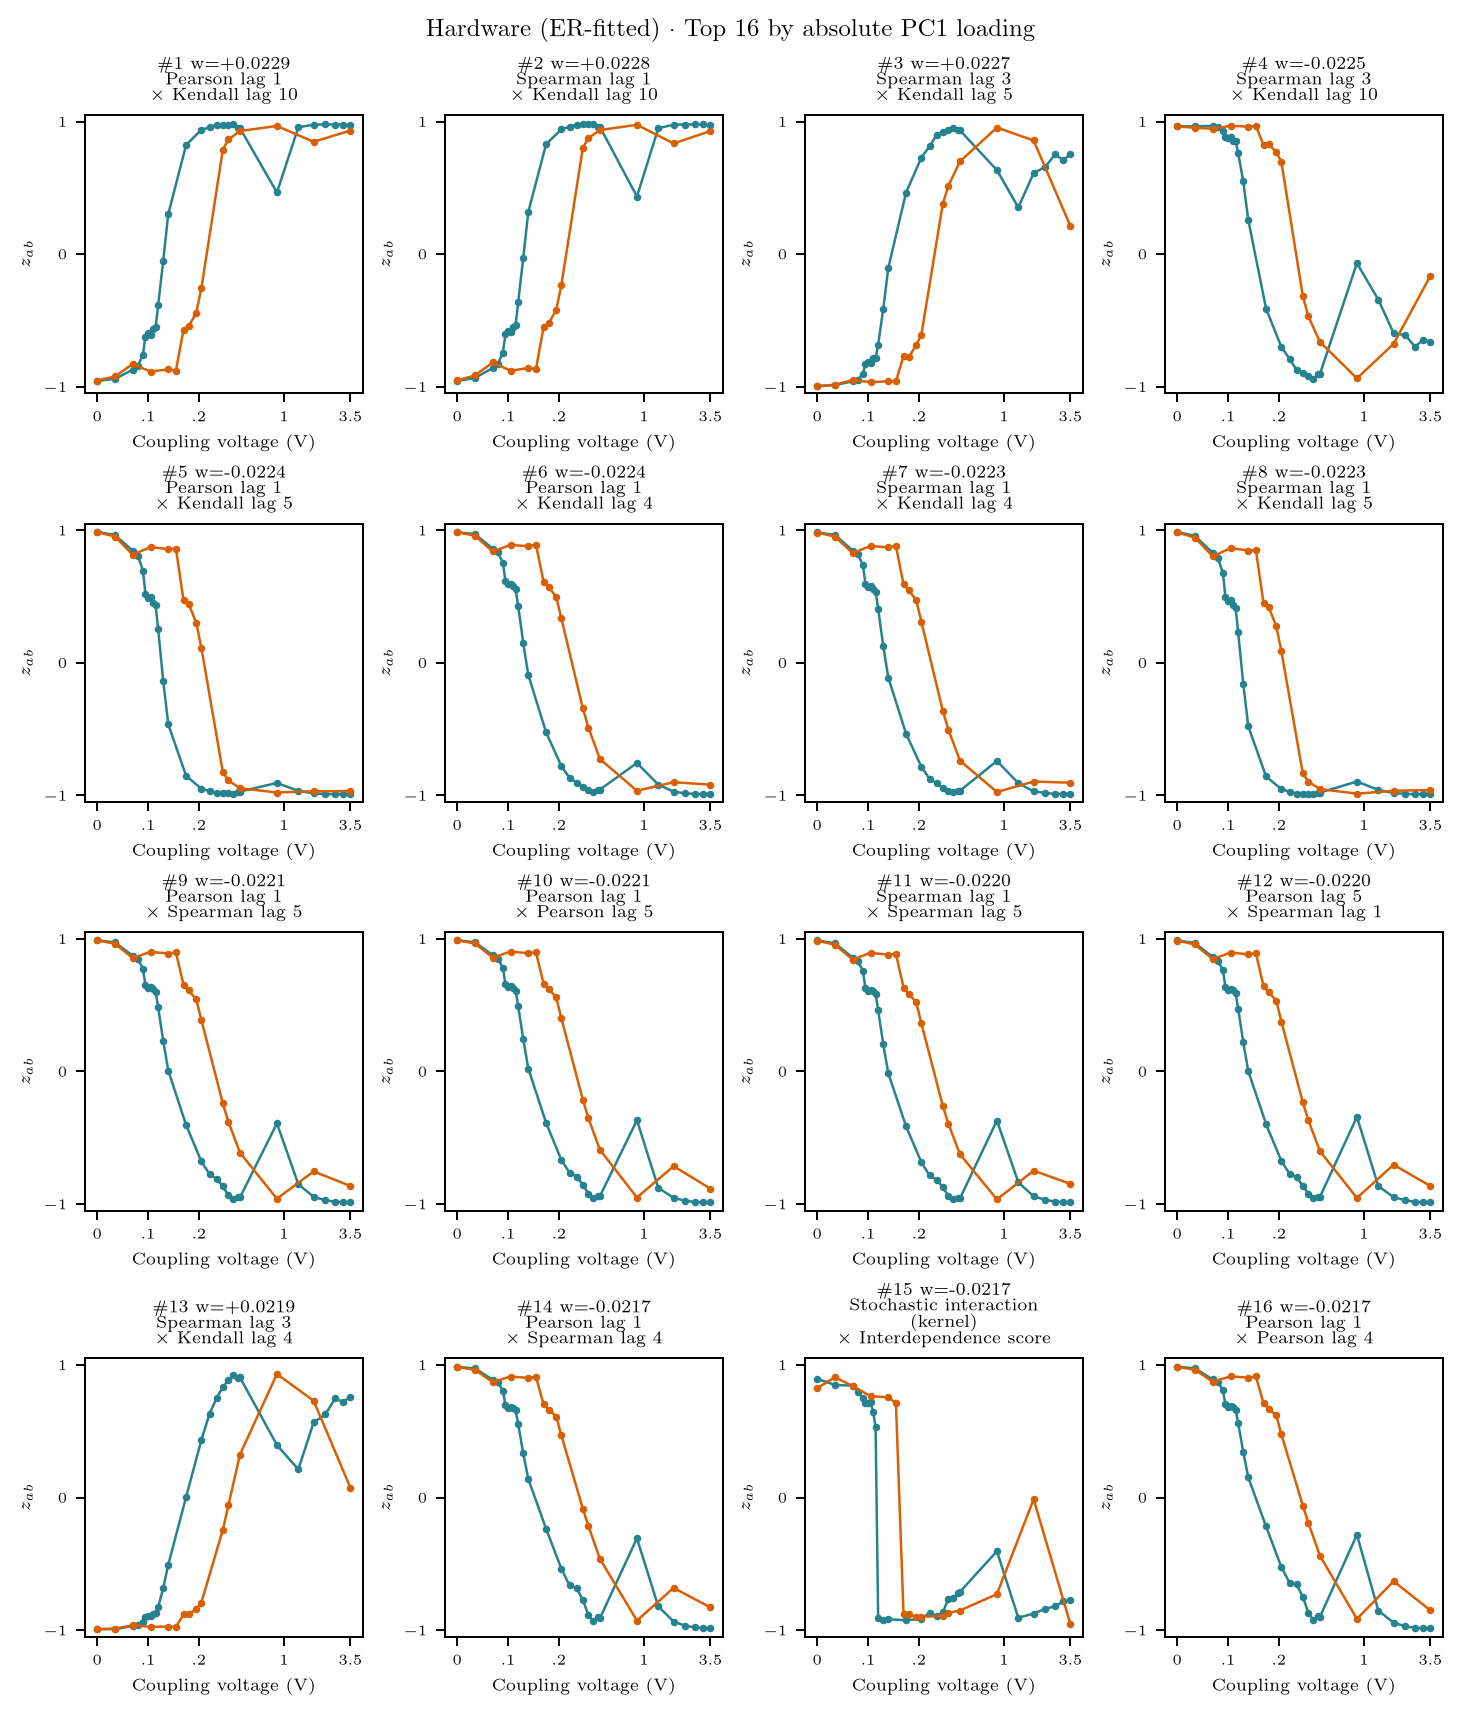

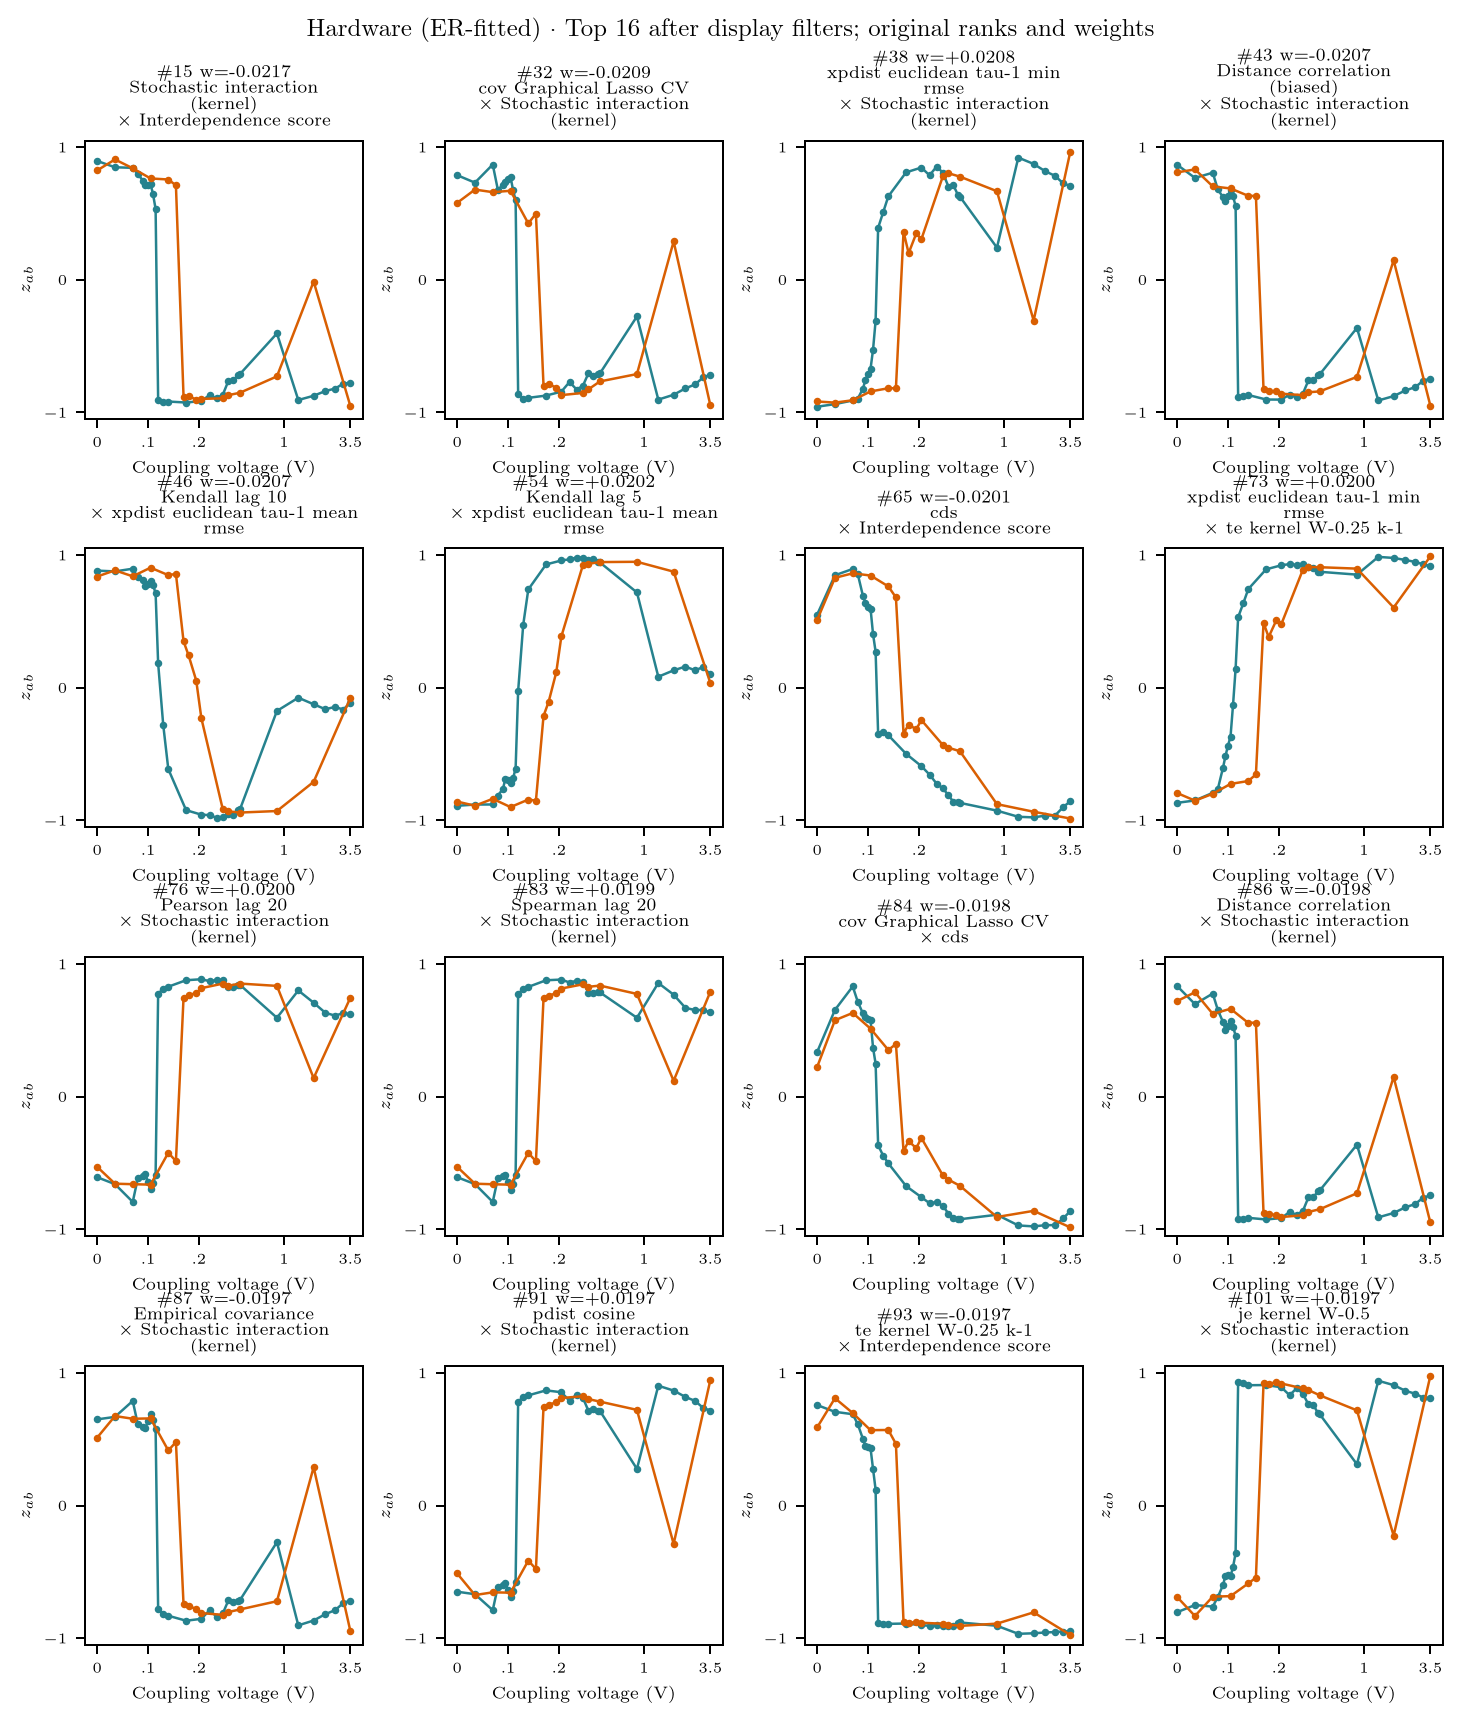

In [10]:
loadings('hardware')

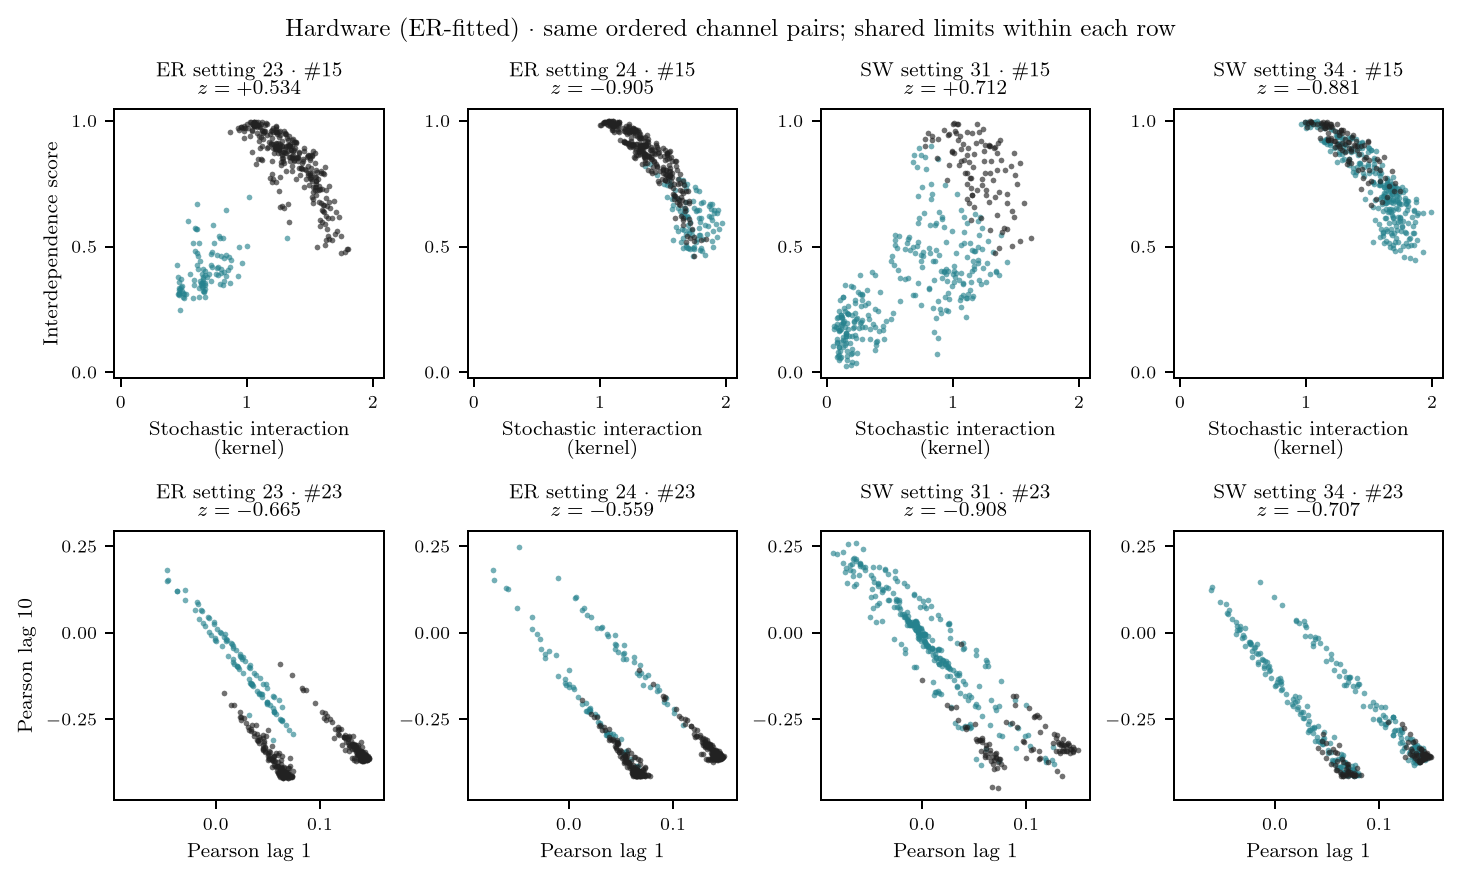

In [11]:
show(edges(banks['hardware'], 'hardware', hardware))

Black edges belonged to the coherent core **before** each topology’s locking transition; teal denotes other pairs, with membership held fixed across each before/after contrast. The SI–IDS reversal is consistent with recruitment of the remaining oscillators into locking. The 2 ms versus 20 ms Pearson pair shows an additional change in lag/spectral organisation, but a smaller change across these particular transitions. SI includes instantaneous and temporal conditional dependence; it is not pure causal flow.

**Do the results make sense?** Yes: the largest PC1 changes coincide with independently measured loss of frequency dispersion in both wirings. This supports sensitivity to an actual collective change. It does not make PC1 a universal synchrony measure or imply a change in the coupling law. There is one recording per setting, and late high-coupling changes need separate interpretation. [Spectral calibration and matched-strength contrasts](../../../empirical/hardware_pilot/notebooks/hardware-pilot-calibrate.ipynb).

**Which contrasts explain dependence character?**

| Contrast | Supported interpretation | Decisive next validation |
|---|---|---|
| Hardware Pearson 2 ms × 20 ms | Best calibrated beyond **mean** strength: ER63/70 have mean Pearson .919662/.919659 but z=.720/.850 (central 9 s). Spectral/phase organisation differs; the frozen three-band explanation passes 40/45 records. | Reproduce in independent sweeps; vary component phase structure at matched power and mean strength, then predict the change in z. This is spectral character, not unique nonlinear coupling. |
| Cross-frequency LCSS × transfer entropy | Most promising richer contrast: A–B predictive dependence rises while waveform similarity barely changes. Current edge examples are illustrative. | Replicate across held seeds; compare coupling-on/off systems matched for frequency, spectra and sensor noise, and a null retaining linear cross-dependence. Persistence beyond that null would support a specifically nonlinear interpretation. |
| Cross-frequency lagged correlations | Well-resolved redistribution of delayed dependence between communities, beyond an overall strength scalar. | Match frequencies/autocorrelation while manipulating phase locking; otherwise frequency pulling remains a sufficient explanation. |
| Hardware SI × IDS | Robust recruitment-associated reorganisation, including both wirings and bandwidth/window checks; not yet strength-independent. | Test strength/spectrum-matched controls and estimator-family agreement before assigning a more specific mechanism. |

The CML signed/absolute-envelope pair is **not** independent evidence of a new mechanism; the transformation itself explains much of its geometry. A successful null test is specific to what the null preserves: [surrogate-method principles](https://arxiv.org/abs/chao-dyn/9909037).

In [12]:
summary = write_receipt(cml, locking, hardware)
display(summary.drop(columns='z_rho'))
print('Figures, exact loading tables, edge replays and source provenance: results/order-parameter-inference/three-systems-261015/')

,system,observed,samples,fit,evaluation,reference
0,CML2D,M32 / N65536,1000,4 development seeds × 9 controls,32 new seeds × 17 controls,Disjoint future period-two Q
1,Noisy 2:1 locking,M=N=24,1000,8 development seeds × 21 controls,8 held seeds × 21 controls,Disjoint future harmonic-locking Q
2,Hardware,M=N=28,5000,29 ER recordings,16 small-world recordings,Measured carrier dispersion; no known universal Q


Figures, exact loading tables, edge replays and source provenance: results/order-parameter-inference/three-systems-261015/
